In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df_gdm = pd.read_csv('../data/raw/gestational_diabetes.csv')

In [85]:
print("\n------------------------------------------------------------------------------\n")

print("Veri Seti Boyutu:", df_gdm.shape)

print("\n------------------------------------------------------------------------------\n")

print("İlk 5 Satır:\n\n", df_gdm.head())

print("\n------------------------------------------------------------------------------\n")


print("Veri Seti Bilgileri:\n") 
df_gdm.info()

print("\n------------------------------------------------------------------------------\n")

print("Eksik Değer Sayıları:\n") 
print(df_gdm.isnull().sum())

print("\n------------------------------------------------------------------------------\n")

print("Tekrarlanan Satır Sayısı:", df_gdm.duplicated().sum())

print("\n------------------------------------------------------------------------------\n")

print("Özet İstatistikler:\n")
print(df_gdm.describe().T)

print("\n------------------------------------------------------------------------------\n")

print("Hedef Değişken (Prediction) Sınıf Dağılımı:\n")
print(df_gdm['Prediction'].value_counts())

print("\n------------------------------------------------------------------------------\n")

print("Prediction Sınıf Oranları (%):\n")
print(df_gdm['Prediction'].value_counts(normalize=True) * 100)

print("\n------------------------------------------------------------------------------\n")


------------------------------------------------------------------------------

Veri Seti Boyutu: (1012, 7)

------------------------------------------------------------------------------

İlk 5 Satır:

     Age  Pregnancy No  Weight  Height   BMI  Heredity  Prediction
0  17.0           1.0    48.0   165.0  17.6         0           0
1  17.0           1.0    49.0   145.0  23.3         0           0
2  17.0           1.0    50.0   140.0  25.5         0           0
3  17.0           1.0    50.0   145.0  23.8         0           0
4  17.0           1.0    49.0   146.0  23.0         0           0

------------------------------------------------------------------------------

Veri Seti Bilgileri:

<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Age           1012 non-null   float64
 1   Pregnancy No  1012 non-null   float64
 2   Weight        1012 non-n


   VERİ SETİNİN GÖRSEL ANALİZİ

-----------------------------------------------------------------------------------------------------------------------------------------------------------

Sınıf Dağılımı (Count Plot)


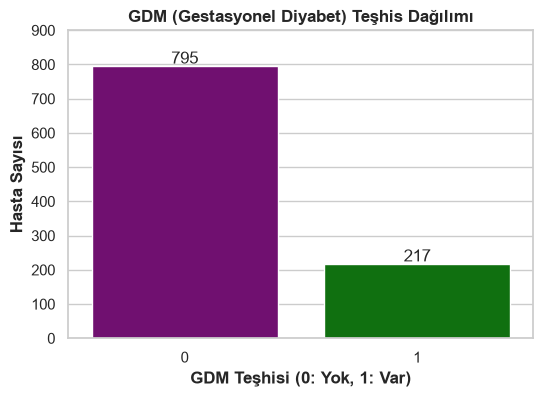


-----------------------------------------------------------------------------------------------------------------------------------------------------------

Sayısal Özelliklerin Dağılımı (Histogram & KDE)


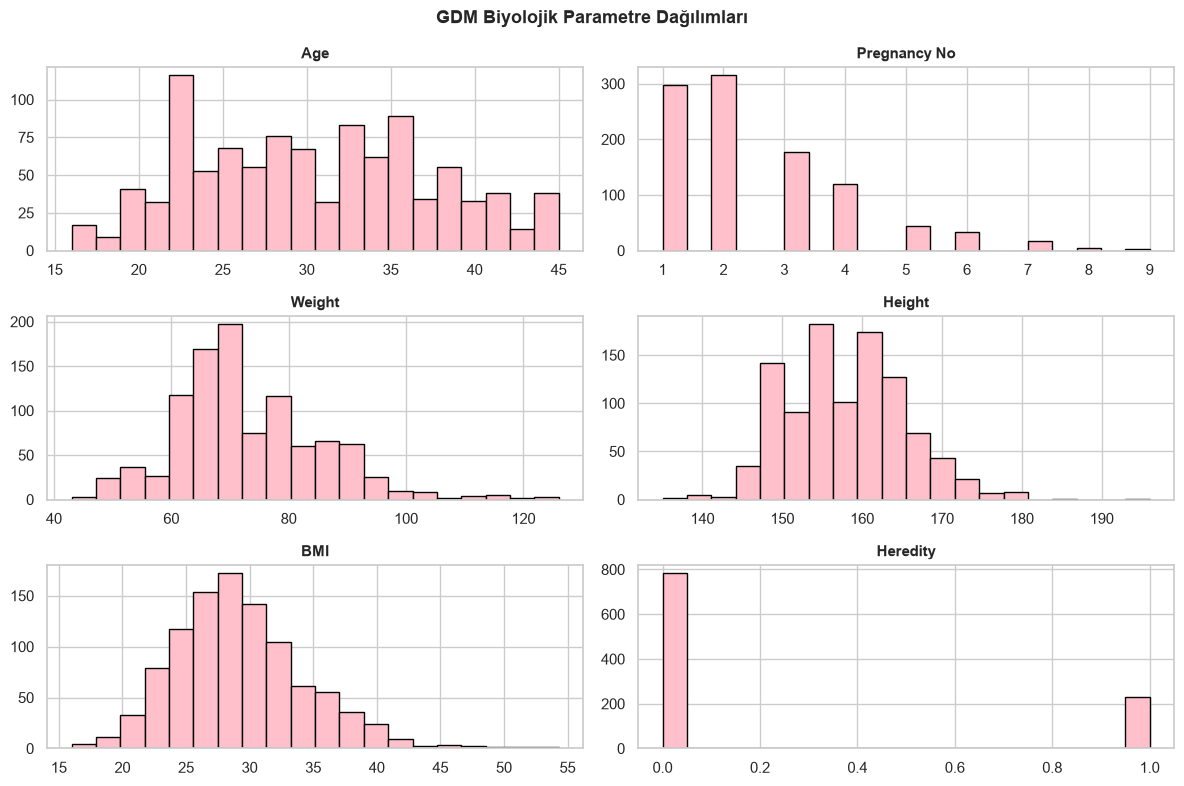


-----------------------------------------------------------------------------------------------------------------------------------------------------------

Aykırı Değer (Outlier) Analizi (Box Plot)


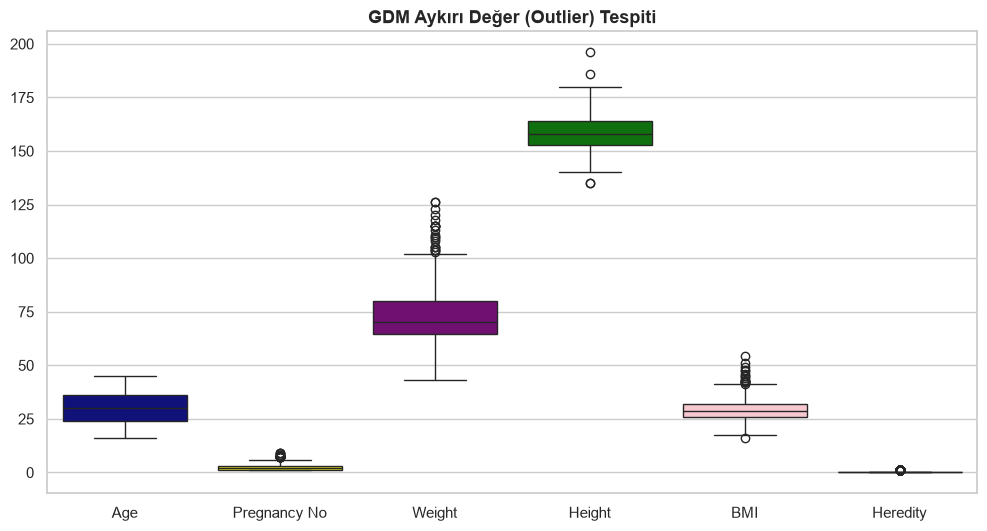


-----------------------------------------------------------------------------------------------------------------------------------------------------------

Korelasyon Matrisi (Heatmap)


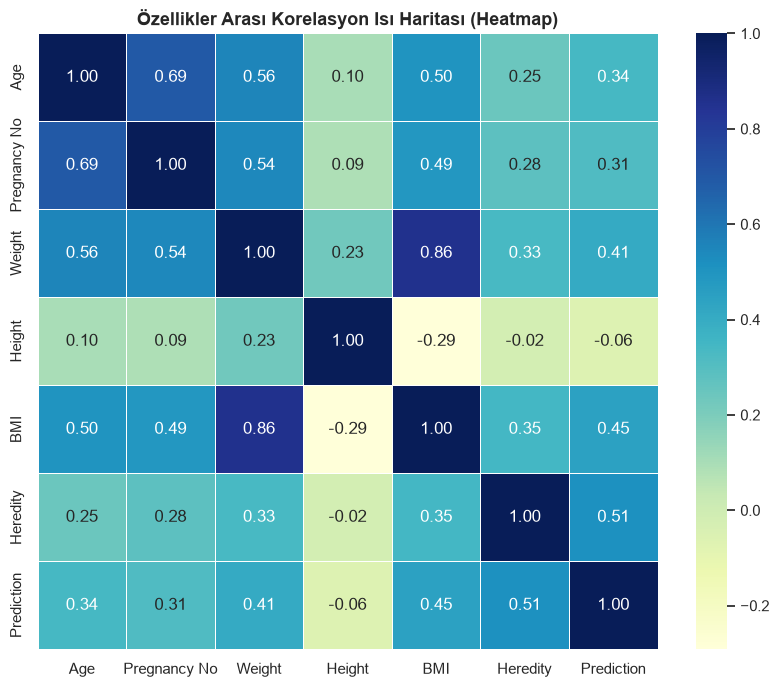


-----------------------------------------------------------------------------------------------------------------------------------------------------------



In [86]:
print("\n   VERİ SETİNİN GÖRSEL ANALİZİ")

import os
os.makedirs("../reports/figures", exist_ok=True)

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Sınıf Dağılımı (Count Plot)")

custom_colors = ['purple', 'green']

plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df_gdm, x="Prediction", hue="Prediction", palette=custom_colors, legend=False)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.title('GDM (Gestasyonel Diyabet) Teşhis Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('GDM Teşhisi (0: Yok, 1: Var)', fontweight="bold")
plt.ylabel('Hasta Sayısı', fontweight="bold")
plt.ylim(0, 900)
plt.yticks(range(0, 901, 100))
plt.savefig("../reports/figures/gdm_countplot.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Sayısal Özelliklerin Dağılımı (Histogram & KDE)")

num_cols_gdm = df_gdm.select_dtypes(include=[np.number]).columns.drop('Prediction')

axes = df_gdm[num_cols_gdm].hist(bins=20, figsize=(12, 8), color='pink', edgecolor='black')
plt.suptitle('GDM Biyolojik Parametre Dağılımları', fontsize=13, fontweight='bold')
for ax in axes.flatten():
    ax.set_title(ax.get_title(), fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig("../reports/figures/gdm_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Aykırı Değer (Outlier) Analizi (Box Plot)")

plt.figure(figsize=(12, 6))
custom_colors = ['darkblue', 'yellow', 'purple', 'green', 'pink', 'orange']
sns.boxplot(data=df_gdm[num_cols_gdm], palette=custom_colors)
plt.title('GDM Aykırı Değer (Outlier) Tespiti', fontsize=13, fontweight='bold')
plt.xticks(rotation=0)
plt.savefig("../reports/figures/gdm_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Korelasyon Matrisi (Heatmap)")

plt.figure(figsize=(10, 8))
sns.heatmap(df_gdm.corr(), annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title('Özellikler Arası Korelasyon Isı Haritası (Heatmap)', fontsize=13, fontweight='bold')
plt.savefig("../reports/figures/gdm_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")